# Basic Calculus for Machine Learning


### 1. Mathematical Functions & Curves


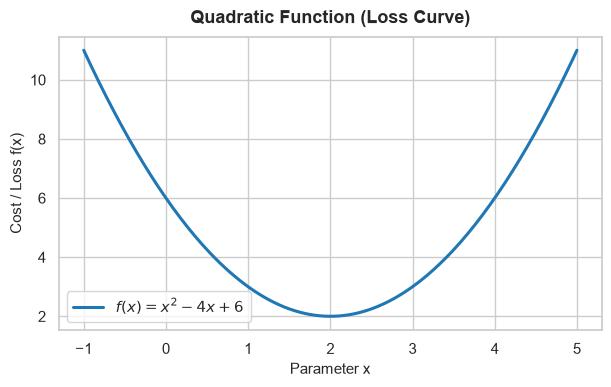

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Quadratic function (standard shape of a Loss curve)
def f(x):
    return x**2 - 4*x + 6

x = np.linspace(-1, 5, 200)
y = f(x)

plt.figure(figsize=(7, 3.8))
plt.plot(x, y, color='#1f77b4', linewidth=2.2, label=r"$f(x) = x^2 - 4x + 6$")
plt.title("Quadratic Function (Loss Curve)", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("Parameter x", fontsize=11)
plt.ylabel("Cost / Loss f(x)", fontsize=11)
plt.legend()
plt.show()


### 2. Concept of Derivative (Numerical vs Analytical)


In [2]:
# Finite difference formula: limit h -> 0 of [f(x + h) - f(x)] / h
def numerical_derivative(func, x, h=1e-5):
    return (func(x + h) - func(x)) / h

# For f(x) = x^2 - 4x + 6, exact analytical derivative is f'(x) = 2x - 4
test_points = [0.0, 2.0, 4.0]

print("Point (x) | Numerical Deriv | Analytical Deriv (2x - 4)")
print("-" * 52)
for pt in test_points:
    num = numerical_derivative(f, pt)
    ana = 2 * pt - 4
    print(f"{pt:^9.1f} | {num:^15.4f} | {ana:^25.4f}")


Point (x) | Numerical Deriv | Analytical Deriv (2x - 4)
----------------------------------------------------
   0.0    |     -4.0000     |          -4.0000         
   2.0    |     0.0000      |          0.0000          
   4.0    |     4.0000      |          4.0000          


### 3. Tangent Line & Slope Visualization


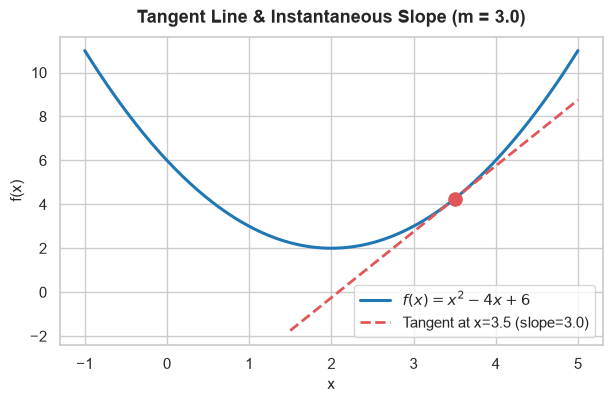

In [3]:
# Point to evaluate tangent
x0 = 3.5
y0 = f(x0)
slope = 2 * x0 - 4  # f'(3.5) = 3.0

# Tangent equation: y = slope * (x - x0) + y0
tangent_x = np.linspace(1.5, 5.0, 100)
tangent_y = slope * (tangent_x - x0) + y0

plt.figure(figsize=(7, 4))
plt.plot(x, y, color='#1f77b4', linewidth=2.2, label=r"$f(x) = x^2 - 4x + 6$")
plt.plot(tangent_x, tangent_y, '--', color='#e15759', linewidth=2, label=f"Tangent at x={x0} (slope={slope:.1f})")
plt.scatter([x0], [y0], color='#e15759', s=90, zorder=5)
plt.title(f"Tangent Line & Instantaneous Slope (m = {slope:.1f})", fontsize=13, fontweight='bold', pad=10)
plt.xlabel("x", fontsize=11)
plt.ylabel("f(x)", fontsize=11)
plt.legend()
plt.show()


### 4. Basic Differentiation Rules (Power Rule)


In [4]:
# Power Rule: d/dx (x^n) = n * x^(n - 1)
# Example: g(x) = 3*x^3 + 5*x^2 - 8*x + 12
# Derivative: g'(x) = 9*x^2 + 10*x - 8

def g(x):
    return 3*x**3 + 5*x**2 - 8*x + 12

def g_deriv(x):
    return 9*x**2 + 10*x - 8

sample_x = 2.0
print(f"Function: g(x) = 3x^3 + 5x^2 - 8x + 12")
print(f"Derivative: g'(x) = 9x^2 + 10x - 8")
print(f"At x = {sample_x}:")
print(f"  Numerical:  {numerical_derivative(g, sample_x):.4f}")
print(f"  Analytical: {g_deriv(sample_x):.4f}")


Function: g(x) = 3x^3 + 5x^2 - 8x + 12
Derivative: g'(x) = 9x^2 + 10x - 8
At x = 2.0:
  Numerical:  48.0002
  Analytical: 48.0000


### 5. Partial Derivatives (Multi-variable Calculus)


In [5]:
# Multi-variable function: f(x, y) = x^2 + 3*x*y + y^2
# Partial w.r.t x: df/dx = 2x + 3y (treating y as constant)
# Partial w.r.t y: df/dy = 3x + 2y (treating x as constant)

def multi_f(x, y):
    return x**2 + 3*x*y + y**2

def partial_x(func, x, y, h=1e-5):
    return (func(x + h, y) - func(x, y)) / h

def partial_y(func, x, y, h=1e-5):
    return (func(x, y + h) - func(x, y)) / h

px, py = 2.0, 3.0
df_dx = partial_x(multi_f, px, py)
df_dy = partial_y(multi_f, px, py)

print(f"Function: f(x, y) = x^2 + 3xy + y^2")
print(f"At point (x={px}, y={py}):")
print(f"  df/dx = {df_dx:.4f} (Analytical: {2*px + 3*py})")
print(f"  df/dy = {df_dy:.4f} (Analytical: {3*px + 2*py})")


Function: f(x, y) = x^2 + 3xy + y^2
At point (x=2.0, y=3.0):
  df/dx = 13.0000 (Analytical: 13.0)
  df/dy = 12.0000 (Analytical: 12.0)


### 6. The Gradient Vector (Steepest Ascent & Descent)


In [6]:
# Gradient vector = [df/dx, df/dy]
grad = np.array([df_dx, df_dy])

print("Gradient Vector (grad f):", grad.round(2))
print("Direction of steepest descent (-grad f):", (-grad).round(2))
print("Magnitude of gradient:", round(np.linalg.norm(grad), 2))


Gradient Vector (grad f): [13. 12.]
Direction of steepest descent (-grad f): [-13. -12.]
Magnitude of gradient: 17.69


### 7. Chain Rule (Deep Learning Backpropagation)


In [7]:
# Chain rule: dz/dx = (dz/du) * (du/dx)
# Example: z = (3x + 2)^2
# Let u = 3x + 2   => du/dx = 3
# Let z = u^2      => dz/du = 2*u
# dz/dx = (2*u) * 3 = 6*(3x + 2)

def inner_u(x):
    return 3*x + 2

def outer_z(u):
    return u**2

def composed(x):
    return outer_z(inner_u(x))

x_val = 1.0
u_val = inner_u(x_val)
dz_du = 2 * u_val
du_dx = 3
chain_rule_result = dz_du * du_dx
numerical_check = numerical_derivative(composed, x_val)

print(f"Evaluating at x = {x_val}:")
print(f"  u = 3x + 2 = {u_val}")
print(f"  dz/du = 2*u = {dz_du}")
print(f"  du/dx = 3")
print(f"  Chain rule (dz/du * du/dx): {chain_rule_result:.4f}")
print(f"  Numerical derivative:       {numerical_check:.4f}")


Evaluating at x = 1.0:
  u = 3x + 2 = 5.0
  dz/du = 2*u = 10.0
  du/dx = 3
  Chain rule (dz/du * du/dx): 30.0000
  Numerical derivative:       30.0001


### 8. Symbolic Differentiation with SymPy


In [8]:
import sympy as sp

x_sym, y_sym = sp.symbols('x y')

# Single variable
poly_expr = 4*x_sym**3 - 5*x_sym**2 + 6*x_sym - 10
poly_diff = sp.diff(poly_expr, x_sym)

print("Expression:", poly_expr)
print("Derivative:", poly_diff)

# Multi-variable partial derivatives
multi_expr = x_sym**2 * y_sym + sp.sin(x_sym) + y_sym**3
print("\nMulti-variable Expression:", multi_expr)
print("Partial w.r.t x (df/dx):", sp.diff(multi_expr, x_sym))
print("Partial w.r.t y (df/dy):", sp.diff(multi_expr, y_sym))


Expression: 4*x**3 - 5*x**2 + 6*x - 10
Derivative: 12*x**2 - 10*x + 6

Multi-variable Expression: x**2*y + y**3 + sin(x)
Partial w.r.t x (df/dx): 2*x*y + cos(x)
Partial w.r.t y (df/dy): x**2 + 3*y**2


### 9. Second Derivative & Minima/Maxima


In [9]:
# For f(x) = x^2 - 4x + 6:
# f'(x) = 2x - 4 = 0 => critical point at x = 2
# f''(x) = 2 > 0 (Positive => Minimum / Convex)

loss_sym = x_sym**2 - 4*x_sym + 6
first_deriv = sp.diff(loss_sym, x_sym)
second_deriv = sp.diff(loss_sym, x_sym, 2)

print("Loss Function:", loss_sym)
print("First Derivative (slope):", first_deriv)
print("Second Derivative (curvature):", second_deriv)
print("Since f''(x) > 0, the critical point x = 2 is a GLOBAL MINIMUM.")


Loss Function: x**2 - 4*x + 6
First Derivative (slope): 2*x - 4
Second Derivative (curvature): 2
Since f''(x) > 0, the critical point x = 2 is a GLOBAL MINIMUM.
